
## Feature Extraction using Jupyter Notebook

This notebook processes the **Twitter US Airline Sentiment Dataset** for sentiment classification by performing:
- Text preprocessing
- Feature extraction
- Basic visualization and correlation analysis


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re
import string
import spacy
from textblob import TextBlob
from sklearn.feature_extraction.text import TfidfVectorizer
from wordcloud import WordCloud
from sklearn.preprocessing import LabelEncoder
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

nlp = spacy.load("en_core_web_sm")


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\alimu\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## Load Dataset

In [ ]:
# Load the dataset
df = pd.read_csv(r"D:\OneDrive - Higher Education Commission\Education\CyberGen\Assignment 2\Tweets.csv")
df.head()


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


## Text Preprocessing

In [17]:

def preprocess(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+|https\S+", '', text, flags=re.MULTILINE)
    text = re.sub(r'@\w+|#\w+', '', text)
    text = re.sub(r'[^A-Za-z\s]', '', text)
    text = " ".join([word for word in text.split() if word not in stop_words])
    doc = nlp(text)
    lemmatized = " ".join([token.lemma_ for token in doc])
    return lemmatized

df['clean_text'] = df['text'].apply(preprocess)
df[['text', 'clean_text']].head()


,text,clean_text
0,@VirginAmerica What @dhepburn said.,say
1,@VirginAmerica plus you've added commercials t...,plus you ve add commercial experience tacky
2,@VirginAmerica I didn't today... Must mean I n...,do not today must mean need take another trip
3,@VirginAmerica it's really aggressive to blast...,really aggressive blast obnoxious entertainmen...
4,@VirginAmerica and it's a really big bad thing...,really big bad thing


## Feature Extraction

In [18]:

df['word_count'] = df['clean_text'].apply(lambda x: len(x.split()))
df['char_count'] = df['clean_text'].apply(len)
df['avg_word_len'] = df['char_count'] / df['word_count']
df['num_exclamations'] = df['text'].apply(lambda x: x.count('!'))
df['num_questions'] = df['text'].apply(lambda x: x.count('?'))
df['has_hashtag'] = df['text'].apply(lambda x: 1 if '#' in x else 0)
df['has_mention'] = df['text'].apply(lambda x: 1 if '@' in x else 0)
df['polarity'] = df['clean_text'].apply(lambda x: TextBlob(x).sentiment.polarity)

df[['word_count', 'char_count', 'avg_word_len', 'num_exclamations', 'num_questions', 'has_hashtag', 'has_mention', 'polarity']].head()


,word_count,char_count,avg_word_len,num_exclamations,num_questions,has_hashtag,has_mention,polarity
0,1,3,3.000000,0,0,0,1,0.00000
1,7,43,6.142857,0,0,0,1,0.00000
2,9,45,5.000000,1,0,0,1,-0.31250
3,10,78,7.800000,0,0,0,1,0.00625
4,4,20,5.000000,0,0,0,1,-0.35000


## TF-IDF Vectorization

In [19]:

tfidf = TfidfVectorizer(max_features=1000)
tfidf_matrix = tfidf.fit_transform(df['clean_text'])

# Convert to DataFrame
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf.get_feature_names_out())
tfidf_df.head()


,aa,able,absolute,absolutely,accept,acceptable,access,accommodate,account,act,...,wtf,yeah,year,yes,yesterday,yet,yo,you,yr,zero
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.331702,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0


## Sentiment Distribution

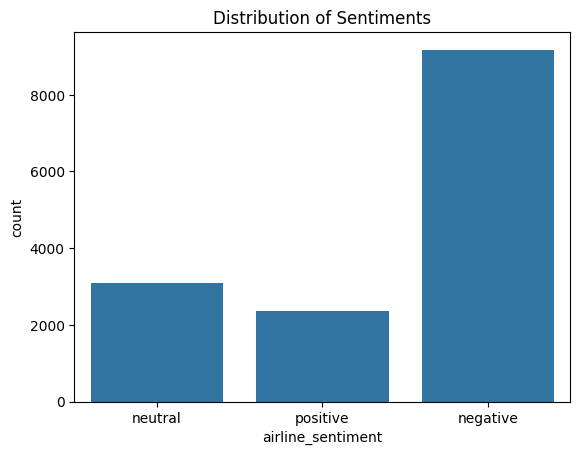

In [20]:

sns.countplot(data=df, x='airline_sentiment')
plt.title("Distribution of Sentiments")
plt.show()


## Correlation with Sentiment

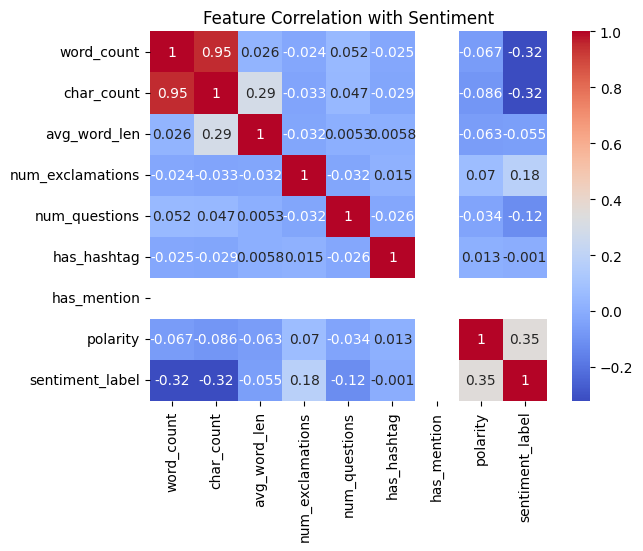

In [21]:

df['sentiment_label'] = LabelEncoder().fit_transform(df['airline_sentiment'])
features = ['word_count', 'char_count', 'avg_word_len', 'num_exclamations', 'num_questions', 'has_hashtag', 'has_mention', 'polarity']
corr = df[features + ['sentiment_label']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Feature Correlation with Sentiment")
plt.show()


## Conclusion


This notebook demonstrates how to:
- Preprocess textual data for sentiment analysis
- Extract both statistical and semantic features
- Use TF-IDF to numerically represent text
- Visualize class distribution and feature correlations

These features can now be used for training a sentiment classifier.
